# Cross-Africa Satellite Prediction: Testing for Label Distribution Shift (NBK 5)

A methodological concern with cross-country prediction is that GDL aggregates surveys from different instruments (DHS, MICS, national surveys) across countries. Apparent prediction accuracy could therefore reflect how unusual a country's label distribution is relative to the training set, not true satellite signal. This notebook tests that concern directly by computing the Wasserstein distance between each held-out country's label distribution and the training distribution, then correlating results with prediction accuracy.

---

### Import statements

In [2]:
import os
import numpy as np
import pandas as pd
from scipy.stats import wasserstein_distance, spearmanr
import matplotlib.pyplot as plt
import helpers

---

### Computing Wasserstein distances

For each (held-out country × outcome) pair, Wasserstein distance measures how much mass must be moved to transform the training label distribution into the country's label distribution. Values are normalized by the training-set standard deviation so distances are comparable across outcomes with different scales.

In [7]:
labels  = pd.read_csv(os.path.join(helpers.PROC, "labels_augmented.csv"))
metrics = pd.read_csv(os.path.join(helpers.OUT,  "loco_metrics.csv"))

shift_rows = []
for outcome in helpers.OUTCOMES:
    if outcome not in labels.columns:
        continue
    sub = labels.dropna(subset=[outcome])
    for ctry in sub["isocode3"].unique():
        test_y  = sub[sub["isocode3"] == ctry][outcome].values
        train_y = sub[sub["isocode3"] != ctry][outcome].values
        if len(test_y) < 2 or len(train_y) < 10:
            continue
        ws = wasserstein_distance(test_y, train_y)
        shift_rows.append({"outcome": outcome, "isocode3": ctry,
                           "wasserstein": ws, "wasserstein_norm": ws / (train_y.std() + 1e-9)})
shift_df = pd.DataFrame(shift_rows)
shift_df.head()

,outcome,isocode3,wasserstein,wasserstein_norm
0,iwi,AGO,11.176890,0.563777
1,iwi,BDI,21.378926,1.087803
2,iwi,BEN,12.093101,0.611661
3,iwi,BFA,10.401609,0.522633
4,iwi,CAF,25.605380,1.309306


A country with a typical label distribution gets a small Wasserstein distance, whereas a country with an unusual distribution gets a large one as it is "tougher" to liken it to the training distribution.

---

### Correlating distribution shift with prediction accuracy

If the model's apparent skill is confounded by label heterogeneity, Wasserstein distance should correlate *negatively* with R², i.e. unusually distributed countries should predict worse.

In [8]:
merged = shift_df.merge(metrics[["outcome","isocode3","r2","country","geo_region"]],
                         on=["outcome","isocode3"], how="inner")
corr_rows = []
for outcome in helpers.OUTCOMES:
    sub = merged[merged["outcome"] == outcome].dropna(subset=["r2"])
    if len(sub) < 5:
        continue
    rho, p = spearmanr(sub["wasserstein_norm"], sub["r2"])
    corr_rows.append({"outcome": outcome, "n_countries": len(sub),
                      "spearman_rho": rho, "pvalue": p})
    print(f"{outcome:<10}  ρ={rho:+.3f}  p={p:.4f}  n={len(sub)}")

corr_df = pd.DataFrame(corr_rows)
corr_df.to_csv(os.path.join(helpers.OUT, "distribution_shift.csv"), index=False)
merged.to_csv (os.path.join(helpers.OUT, "distribution_shift_per_country.csv"), index=False)

iwi         ρ=-0.755  p=0.0000  n=43
iwipov70    ρ=-0.723  p=0.0000  n=42
stunting    ρ=-0.662  p=0.0000  n=40
u5mort      ρ=-0.531  p=0.0004  n=41
dtp3age1    ρ=-0.869  p=0.0000  n=23
gap_eye     ρ=-0.687  p=0.0000  n=41
shdi        ρ=-0.560  p=0.0000  n=53


Strongly negative Spearman correlations across all outcomes indicate that label distribution shift is a genuine confounder. As such, countries with atypical outcome distributions are systematically harder to predict regardless of satellite signal.

---

### Visualizing the Wasserstein–R² relationship per outcome

We can plot a small-multiples scatter plot having one panel per outcome, with Wasserstein distance (normalized by training-set standard deviation) on the x-axis and R² on the y-axis. The y-axis is clipped at the 10th percentile (or −2, whichever is less extreme) so the main cluster of countries is visible. This is so that extreme outliers are reflected in the per-panel Spearman ρ shown in each title but cropped from the view. Nigeria is highlighted to show where it sits in the shift-vs-accuracy space.

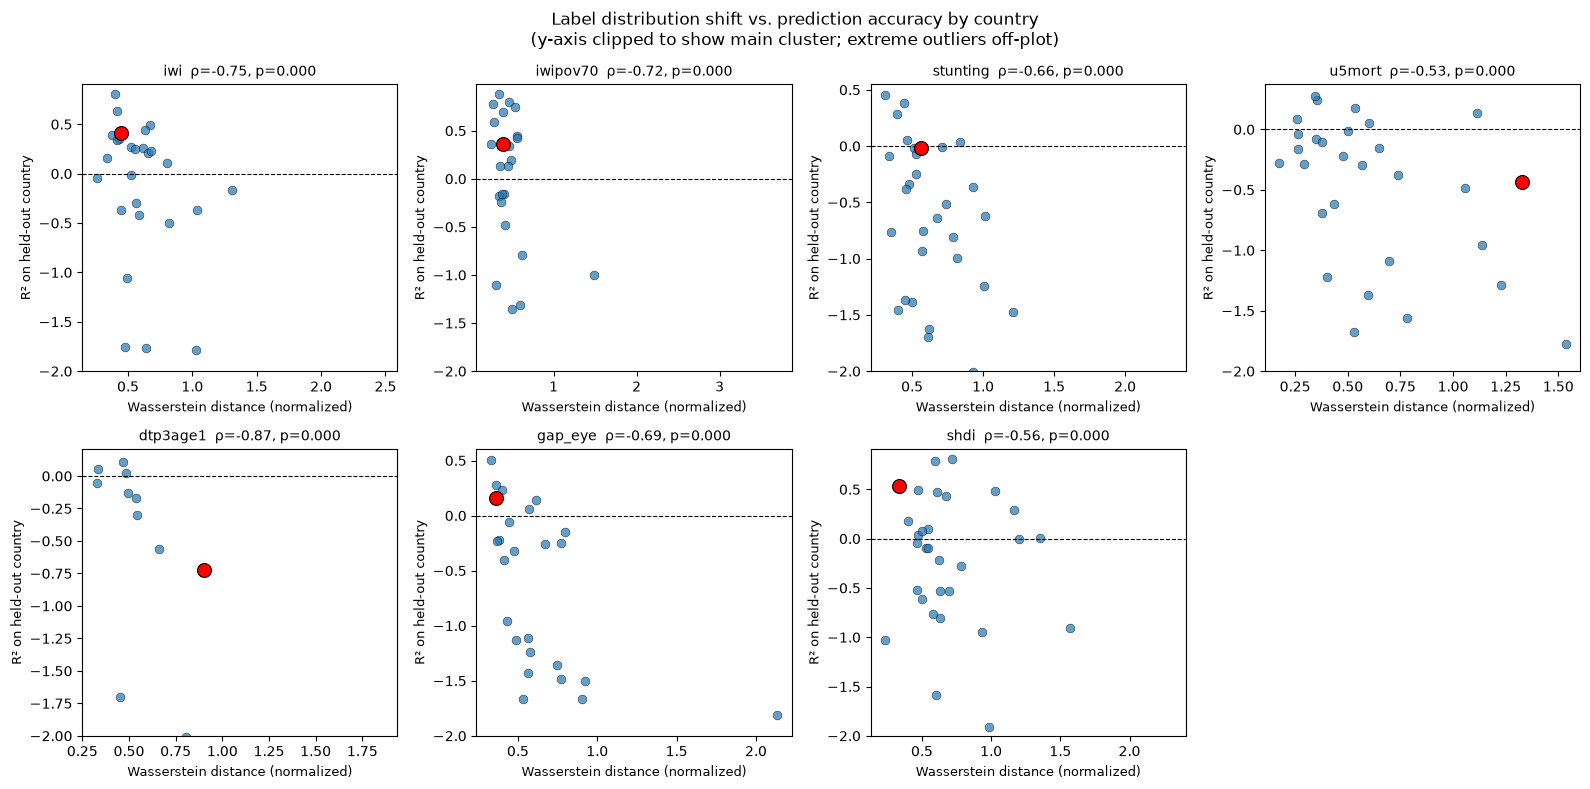

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, outcome in enumerate(helpers.OUTCOMES):
    sub = merged[merged["outcome"] == outcome].dropna(subset=["r2"])
    if len(sub) < 5:
        axes[i].set_visible(False)
        continue

    axes[i].scatter(sub["wasserstein_norm"], sub["r2"],
                    alpha=0.7, s=40, edgecolors="k", linewidths=0.4)
    nga = sub[sub["isocode3"] == "NGA"]
    if len(nga):
        axes[i].scatter(nga["wasserstein_norm"], nga["r2"],
                        color="red", s=100, edgecolors="k", linewidths=0.8,
                        label="Nigeria", zorder=3)

    y_lo = max(np.percentile(sub["r2"], 10), -2)
    y_hi = min(sub["r2"].max() + 0.1, 1.0)
    axes[i].set_ylim(y_lo, y_hi)

    axes[i].axhline(0, color="black", linewidth=0.8, linestyle="--")
    rho, p = spearmanr(sub["wasserstein_norm"], sub["r2"])
    axes[i].set_title(f"{outcome}  ρ={rho:+.2f}, p={p:.3f}", fontsize=10)
    axes[i].set_xlabel("Wasserstein distance (normalized)", fontsize=9)
    axes[i].set_ylabel("R² on held-out country", fontsize=9)

axes[-1].set_visible(False)
plt.suptitle("Label distribution shift vs. prediction accuracy by country\n"
             "(y-axis clipped to show main cluster; extreme outliers off-plot)",
             fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(helpers.FIG, "fig_distribution_shift.png"), dpi=150)
plt.show()

Spearman correlations between Wasserstein distance and R² are strongly negative across every outcome (ρ from −0.53 to −0.87, p ≈ 0). The clipped view makes the structural pattern visible: countries with larger Wasserstein distance cluster toward the bottom of each panel. For wealth, poverty, and SHDI, Nigeria sits clearly in the favorable quadrant (low Wasserstein, R² ≥ 0). For stunting, gender schooling, and SHDI, the downward slope is particularly clean. DTP3 shows the strongest correlation (ρ = −0.87), reflecting that its narrower country coverage magnifies the shift-vs-accuracy relationship.

---